In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers,models,regularizers
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint
from sklearn.metrics import classification_report,confusion_matrix


In [5]:
#loading dataset
(X_train,y_train),(X_test,y_test)=(tf.keras.datasets.cifar100.load_data(
    label_mode='fine'
))

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 2533s 15us/step


In [6]:
print('Training images:',X_train.shape)
print('Training labels:',y_train.shape)
print('Testing images:',X_test.shape)
print('Testing labels:',y_test.shape)

print('Data Type:',X_train.dtype)
print('Minimum pixel value:',X_train.min())
print('Maximum pixel value:',X_train.max())

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)
Data Type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


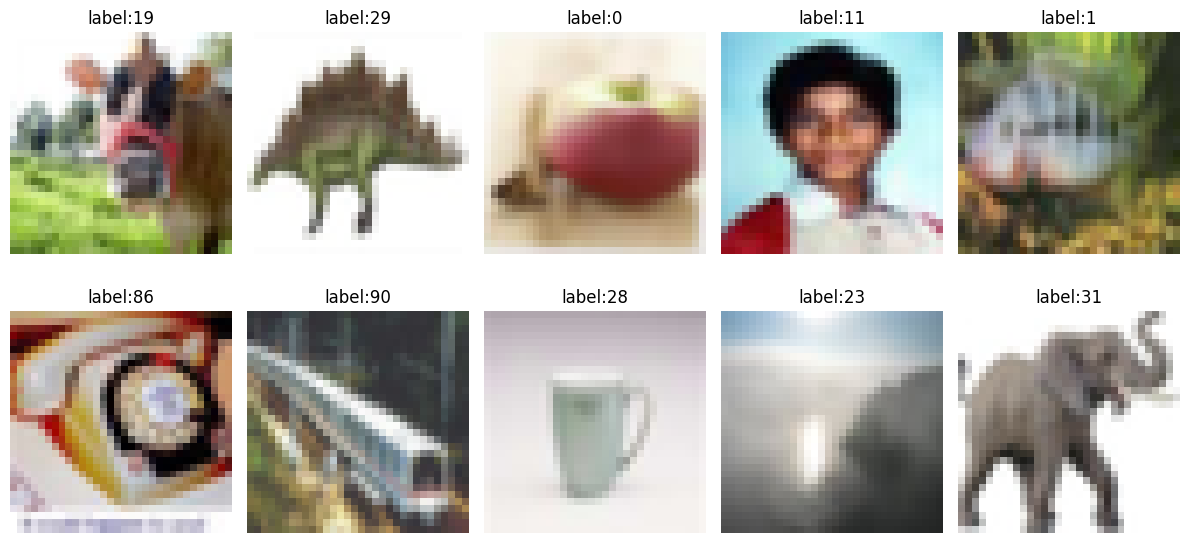

In [7]:
#Display sample images
plt.figure(figsize=(12,6))

for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(X_train[i])
  plt.title(f'label:{y_train[i][0]}')
  plt.axis('off')
plt.tight_layout()
plt.show()

In [8]:
#preprocess the images
X_train=X_train.astype('float32')/255.0
X_test=X_test.astype('float32')/255.0

print('Training data shape:',X_train.shape)
print('Testing data shape:',X_test.shape)

print('Minimum pixel value:',X_train.min())
print('Maximum pixel value:',X_train.max())

Training data shape: (50000, 32, 32, 3)
Testing data shape: (10000, 32, 32, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [9]:
#CNN Architecture

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(
        32,
        (3, 3),
        activation='relu',
        padding='same',
        kernel_initializer='he_normal'
    ),
    layers.BatchNormalization(),
    layers.Conv2D(
        32, (3, 3),
        activation='relu',
        padding='same',
        kernel_initializer='he_normal'
    ),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    layers.Conv2D(
        64, (3, 3),
        activation='relu',
        padding='same',
        kernel_initializer='he_normal'
    ),
    layers.BatchNormalization(),
    layers.Conv2D(
        64, (3, 3),
        activation='relu',
        padding='same',
        kernel_initializer='he_normal'
    ),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(
        128,
        activation='relu',
        kernel_initializer='he_normal',
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.5),
    layers.Dense(100, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 603,268 (2.30 MB)

 Trainable params: 603,076 (2.30 MB)

 Non-trainable params: 192 (768.00 B)

In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print('custom CNN compiled successfully')

custom CNN compiled successfully


In [11]:
#Earlystopping & checkpoints

early_stop=EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
checkpoint=ModelCheckpoint(
    'best_custom_cnn.keras',
    monitor='val_loss',
    save_best_only=True
)
print('Executed Successfully')

Executed Successfully


In [12]:
#Model Training

history=model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop,checkpoint],
    verbose=1
)

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 22ms/step - accuracy: 0.0081 - loss: 4.7538 - val_accuracy: 0.0076 - val_loss: 4.6573
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.0085 - loss: 4.6309 - val_accuracy: 0.0070 - val_loss: 4.6184
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.0095 - loss: 4.6231 - val_accuracy: 0.0072 - val_loss: 4.6165
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.0096 - loss: 4.6181 - val_accuracy: 0.0070 - val_loss: 4.6237
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.0095 - loss: 4.6124 - val_accuracy: 0.0070 - val_loss: 4.6088


In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title(' Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()


In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title(' Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()


In [ ]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Custom CNN Test Loss:", test_loss)
print("Custom CNN Test Accuracy:", test_accuracy)
print("Custom CNN Test Accuracy (%):", test_accuracy * 100)


In [ ]:
#VGG-16
vgg16_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),


    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),


    layers.Flatten(),
    layers.Dense(4096, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(4096, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(100, activation='softmax')
])

vgg16_model.summary()


In [ ]:

vgg16_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("VGG-16 compiled successfully!")


In [ ]:

vgg_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

vgg_checkpoint = ModelCheckpoint(
    'best_vgg16.keras',
    monitor='val_loss',
    save_best_only=True
)


In [19]:

vgg_history = vgg16_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    callbacks=[vgg_early_stop, vgg_checkpoint],
    verbose=1
)


Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 62s 67ms/step - accuracy: 0.0091 - loss: 4.6064 - val_accuracy: 0.0088 - val_loss: 4.6061
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.0088 - loss: 4.6057 - val_accuracy: 0.0078 - val_loss: 4.6067
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - accuracy: 0.0083 - loss: 4.6056 - val_accuracy: 0.0082 - val_loss: 4.6072
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.0096 - loss: 4.6056 - val_accuracy: 0.0070 - val_loss: 4.6073


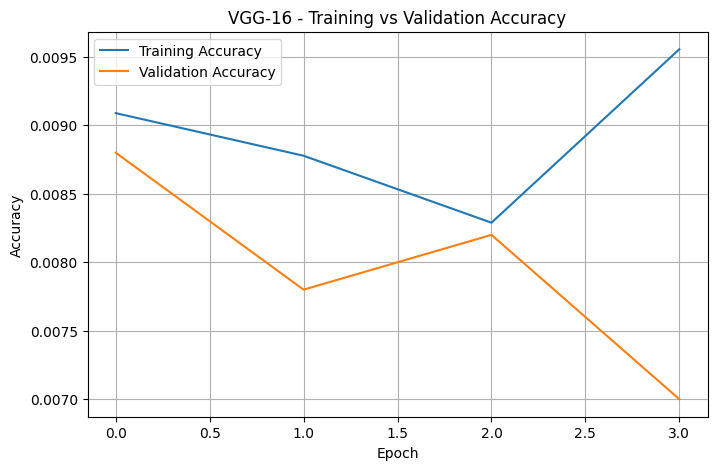

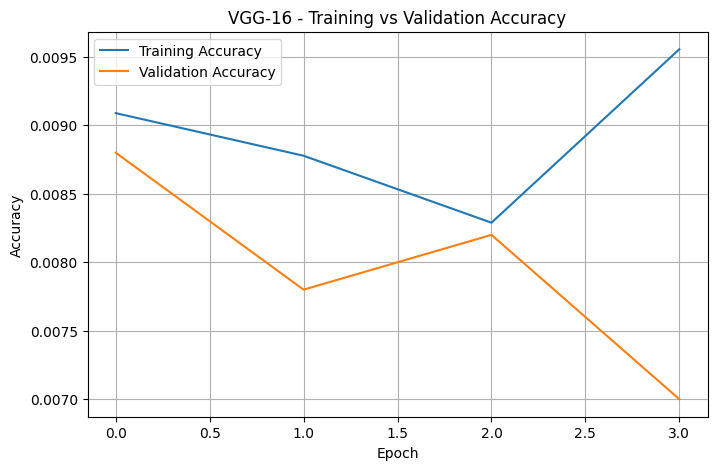

In [20]:

plt.figure(figsize=(8, 5))

plt.plot(vgg_history.history['accuracy'], label='Training Accuracy')
plt.plot(vgg_history.history['val_accuracy'], label='Validation Accuracy')

plt.title('VGG-16 - Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


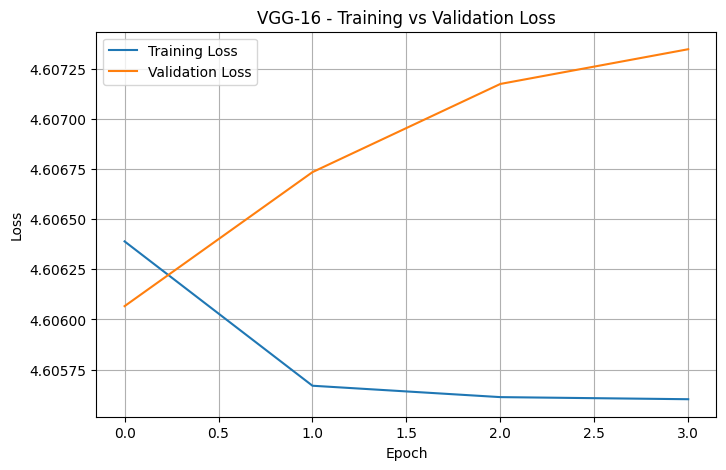

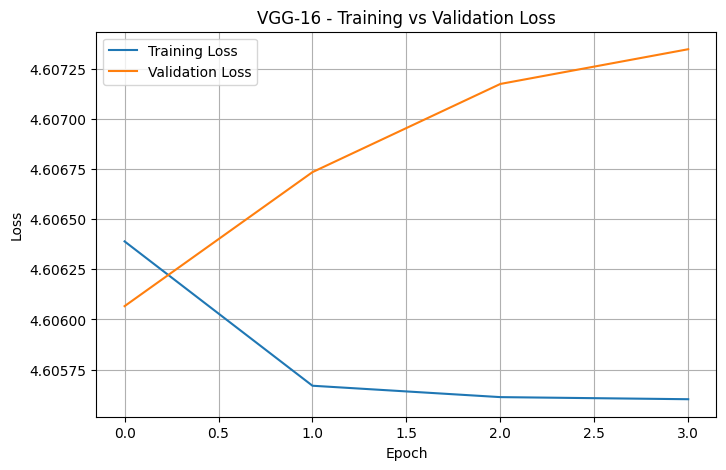

In [21]:

plt.figure(figsize=(8, 5))

plt.plot(vgg_history.history['loss'], label='Training Loss')
plt.plot(vgg_history.history['val_loss'], label='Validation Loss')

plt.title('VGG-16 - Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


In [22]:

vgg_test_loss, vgg_test_accuracy = vgg16_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("VGG-16 Test Loss:", vgg_test_loss)
print("VGG-16 Test Accuracy:", vgg_test_accuracy)
print("VGG-16 Test Accuracy (%):", vgg_test_accuracy * 100)


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.0100 - loss: 4.6052
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.0100 - loss: 4.6052
VGG-16 Test Loss: 4.605212688446045
VGG-16 Test Accuracy: 0.009999999776482582
VGG-16 Test Accuracy (%): 0.9999999776482582
VGG-16 Test Loss: 4.605212688446045
VGG-16 Test Accuracy: 0.009999999776482582
VGG-16 Test Accuracy (%): 0.9999999776482582


In [23]:
#Comparing both models

comparison = pd.DataFrame({
    "Model": ["Custom CNN", "VGG-16"],
    "Test Accuracy (%)": [
        test_accuracy * 100,
        vgg_test_accuracy * 100
    ],
    "Test Loss": [
        test_loss,
        vgg_test_loss
    ]
})

print(comparison.to_string(index=False))


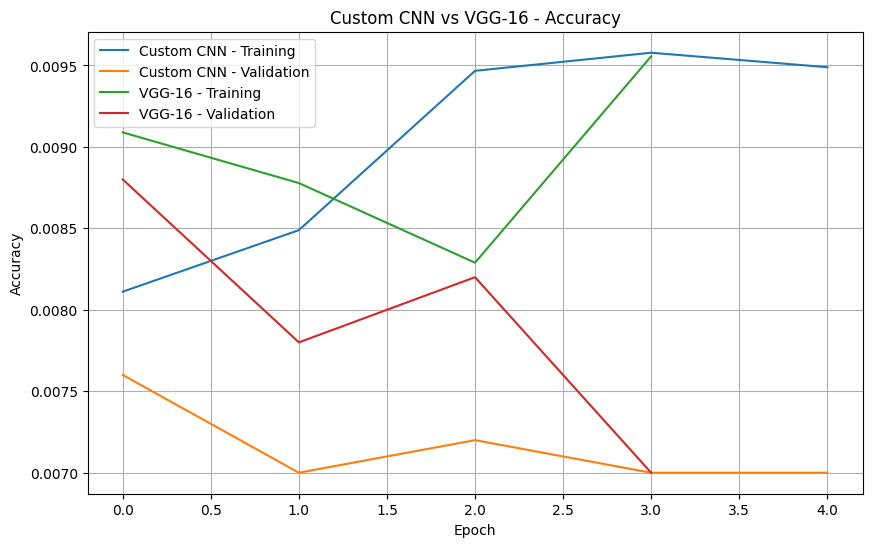

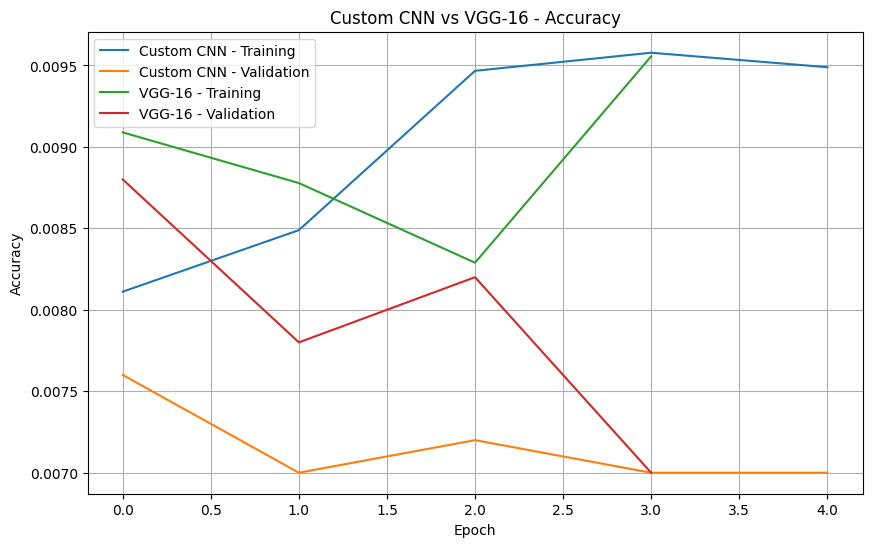

In [24]:

plt.figure(figsize=(10, 6))

plt.plot(history.history["accuracy"],
         label="Custom CNN - Training")
plt.plot(history.history["val_accuracy"],
         label="Custom CNN - Validation")

plt.plot(vgg_history.history["accuracy"],
         label="VGG-16 - Training")
plt.plot(vgg_history.history["val_accuracy"],
         label="VGG-16 - Validation")

plt.title("Custom CNN vs VGG-16 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()
